# Project 23: Agentic AI for Intelligent Business Process Automation
## Notebook 01 — Data Understanding & Exploratory Data Analysis

**Dataset:** Walmart M5 Forecasting Dataset

**Objective:** Explore historical sales, product prices, and calendar data to understand demand patterns and prepare for demand forecasting.

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
calendar = pd.read_csv("C:\\Projects\\23_Agentic_Business_AI\\data\\calendar.csv")
prices = pd.read_csv("C:\\Projects\\23_Agentic_Business_AI\\data\\sell_prices.csv")
sales = pd.read_csv("C:\\Projects\\23_Agentic_Business_AI\\data\\sales_train_validation.csv")

# Display dataset dimensions
print("Calendar:", calendar.shape)
print("Prices:", prices.shape)
print("Sales:", sales.shape)


Calendar: (1969, 14)
Prices: (6841121, 4)
Sales: (30490, 1919)


### 2.1 Calendar Dataset Overview

In [2]:
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


### 2.2 Data Types and Missing Values


In [3]:

calendar.info()

calendar.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          1969 non-null   object
 1   wm_yr_wk      1969 non-null   int64 
 2   weekday       1969 non-null   object
 3   wday          1969 non-null   int64 
 4   month         1969 non-null   int64 
 5   year          1969 non-null   int64 
 6   d             1969 non-null   object
 7   event_name_1  162 non-null    object
 8   event_type_1  162 non-null    object
 9   event_name_2  5 non-null      object
 10  event_type_2  5 non-null      object
 11  snap_CA       1969 non-null   int64 
 12  snap_TX       1969 non-null   int64 
 13  snap_WI       1969 non-null   int64 
dtypes: int64(7), object(7)
memory usage: 215.5+ KB


date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

### 2.3 Duplicate Records and Date Coverage

In [5]:

# Check duplicate rows
print("Duplicate rows:", calendar.duplicated().sum())

# Check duplicate dates and day identifiers
print("Duplicate dates:", calendar["date"].duplicated().sum())
print("Duplicate day IDs:", calendar["d"].duplicated().sum())

# Check date coverage
print("Start date:", calendar["date"].min())
print("End date:", calendar["date"].max())


Duplicate rows: 0
Duplicate dates: 0
Duplicate day IDs: 0
Start date: 2011-01-29
End date: 2016-06-19


In [6]:

# Convert to datetime for validation
calendar["date"] = pd.to_datetime(calendar["date"])

# Generate expected daily dates
expected_dates = pd.date_range(
    start=calendar["date"].min(),
    end=calendar["date"].max(),
    freq="D"
)

# Identify missing dates
missing_dates = expected_dates.difference(calendar["date"])

print("Expected days:", len(expected_dates))
print("Actual days:", len(calendar))
print("Missing dates:", len(missing_dates))


Expected days: 1969
Actual days: 1969
Missing dates: 0


## 3. Selling Prices Dataset Exploration
### 3.1 Dataset Overview

In [7]:

# Display the first five rows
prices.head()


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


### 3.2 Data Types and Missing Values

In [8]:

# Dataset information
prices.info()

# Missing values
print("\nMissing Values:")
print(prices.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    object 
 1   item_id     object 
 2   wm_yr_wk    int64  
 3   sell_price  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 208.8+ MB

Missing Values:
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64


### 3.3 Duplicate Records and Key Uniqueness

In [9]:

# Check exact duplicate rows
print("Exact duplicate rows:",
      prices.duplicated().sum())

# Check duplicate product-store-week combinations
print("Duplicate business keys:",
      prices.duplicated(
          subset=["store_id", "item_id", "wm_yr_wk"]
      ).sum())


Exact duplicate rows: 0
Duplicate business keys: 0


### 3.4 Selling Price Distribution

In [10]:

# Summary statistics for selling prices
prices["sell_price"].describe()


count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

### 3.5 Selling Price Distribution Visualization

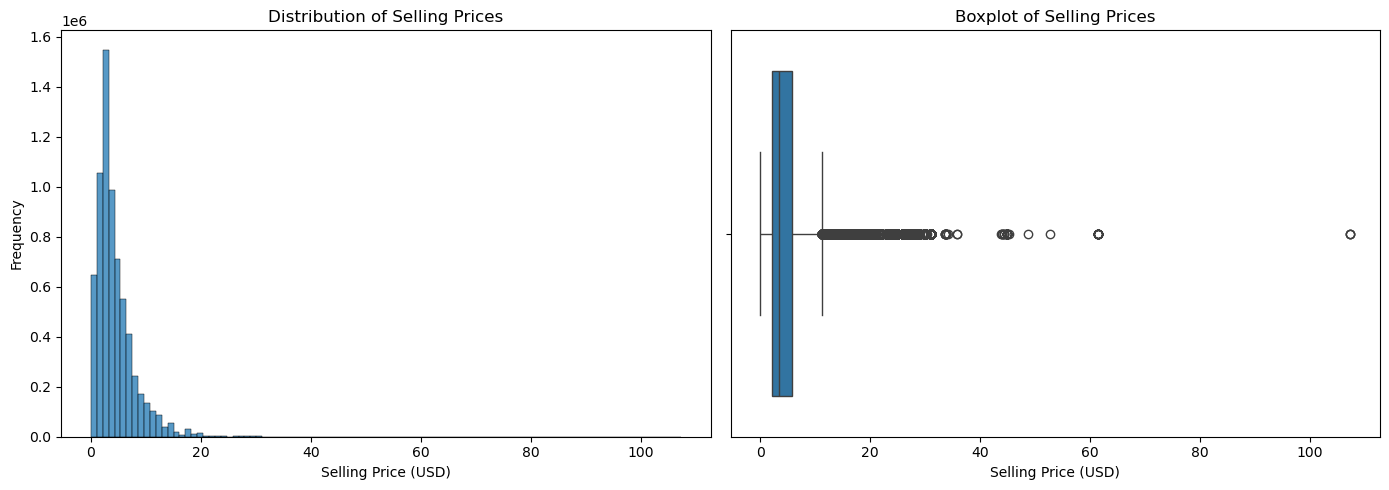

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    prices["sell_price"],
    bins=100,
    ax=axes[0]
)
axes[0].set_title("Distribution of Selling Prices")
axes[0].set_xlabel("Selling Price (USD)")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(
    x=prices["sell_price"],
    ax=axes[1]
)
axes[1].set_title("Boxplot of Selling Prices")
axes[1].set_xlabel("Selling Price (USD)")

plt.tight_layout()
plt.show()


### 3.6 Selling Price Outlier Analysis

In [12]:

Q1 = prices["sell_price"].quantile(0.25)
Q3 = prices["sell_price"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = prices[prices["sell_price"] > upper_bound]

print(f"Upper bound: ${upper_bound:.2f}")
print(f"Outlier records: {len(outliers):,}")
print(f"Outlier percentage: {len(outliers) / len(prices) * 100:.2f}%")


Upper bound: $11.33
Outlier records: 303,640
Outlier percentage: 4.44%


### 3.7 Product and Store Coverage

In [13]:

print("Unique stores:", prices["store_id"].nunique())
print("Unique products:", prices["item_id"].nunique())

print("\nStores:")
print(prices["store_id"].unique())

print("\nProducts per store:")
print(prices.groupby("store_id")["item_id"].nunique())


Unique stores: 10
Unique products: 3049

Stores:
['CA_1' 'CA_2' 'CA_3' 'CA_4' 'TX_1' 'TX_2' 'TX_3' 'WI_1' 'WI_2' 'WI_3']

Products per store:
store_id
CA_1    3049
CA_2    3049
CA_3    3049
CA_4    3049
TX_1    3049
TX_2    3049
TX_3    3049
WI_1    3049
WI_2    3049
WI_3    3049
Name: item_id, dtype: int64


### 3.8 Weekly Price Coverage

In [14]:

# Number of weeks per product-store combination
weekly_coverage = (
    prices.groupby(["store_id", "item_id"])["wm_yr_wk"]
    .nunique()
)

print("Weekly Price Coverage:")
print(weekly_coverage.describe())

print("\nTotal unique weeks:")
print(prices["wm_yr_wk"].nunique())


Weekly Price Coverage:
count    30490.000000
mean       224.372614
std         68.000808
min         19.000000
25%        173.000000
50%        260.000000
75%        282.000000
max        282.000000
Name: wm_yr_wk, dtype: float64

Total unique weeks:
282



## 4. Historical Sales Dataset Exploration
### 4.1 Dataset Overview


In [15]:

# Inspect product identifiers and first sales days
sales.iloc[:5, :12]


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0


### 4.2 Product Categories and Departments

In [16]:

print("Unique categories:")
print(sales["cat_id"].unique())

print("\nUnique departments:")
print(sales["dept_id"].unique())

print("\nProducts per category:")
print(
    sales.groupby("cat_id")["item_id"].nunique()
)

print("\nProduct-store series per category:")
print(sales["cat_id"].value_counts())


Unique categories:
['HOBBIES' 'HOUSEHOLD' 'FOODS']

Unique departments:
['HOBBIES_1' 'HOBBIES_2' 'HOUSEHOLD_1' 'HOUSEHOLD_2' 'FOODS_1' 'FOODS_2'
 'FOODS_3']

Products per category:
cat_id
FOODS        1437
HOBBIES       565
HOUSEHOLD    1047
Name: item_id, dtype: int64

Product-store series per category:
cat_id
FOODS        14370
HOUSEHOLD    10470
HOBBIES       5650
Name: count, dtype: int64


### 4.3 Missing Values and Duplicate Validation

In [17]:

# Identify daily sales columns
day_cols = sales.filter(regex=r"^d_\d+$").columns

print("Daily sales columns:", len(day_cols))

# Missing values
print("Total missing values:", sales.isna().sum().sum())
print("Missing daily sales values:",
      sales[day_cols].isna().sum().sum())

# Duplicate records
print("Duplicate rows:", sales.duplicated().sum())
print("Duplicate series IDs:", sales["id"].duplicated().sum())

# Duplicate product-store combinations
print(
    "Duplicate product-store combinations:",
    sales.duplicated(subset=["item_id", "store_id"]).sum()
)


Daily sales columns: 1913
Total missing values: 0
Missing daily sales values: 0
Duplicate rows: 0
Duplicate series IDs: 0
Duplicate product-store combinations: 0


### 4.4 Zero-Sales Analysis

In [18]:

# Total daily sales observations
total_observations = sales[day_cols].size

# Count zero-sales observations
zero_sales = (sales[day_cols] == 0).sum().sum()

# Calculate zero-sales percentage
zero_percentage = zero_sales / total_observations * 100

print(f"Total observations: {total_observations:,}")
print(f"Zero-sales observations: {zero_sales:,}")
print(f"Zero-sales percentage: {zero_percentage:.2f}%")


Total observations: 58,327,370
Zero-sales observations: 39,777,094
Zero-sales percentage: 68.20%


### 4.5 Zero-Sales Distribution by Product Category

In [19]:

# Calculate zero-sales percentage for each category
category_zero_rates = {}

for category, group in sales.groupby("cat_id"):
    values = group[day_cols].to_numpy()

    zero_rate = (values == 0).sum() / values.size * 100

    category_zero_rates[category] = zero_rate

# Display results
for category, rate in category_zero_rates.items():
    print(f"{category}: {rate:.2f}%")


FOODS: 62.02%
HOBBIES: 77.28%
HOUSEHOLD: 71.77%


### 4.6 Overall Daily Sales Trends

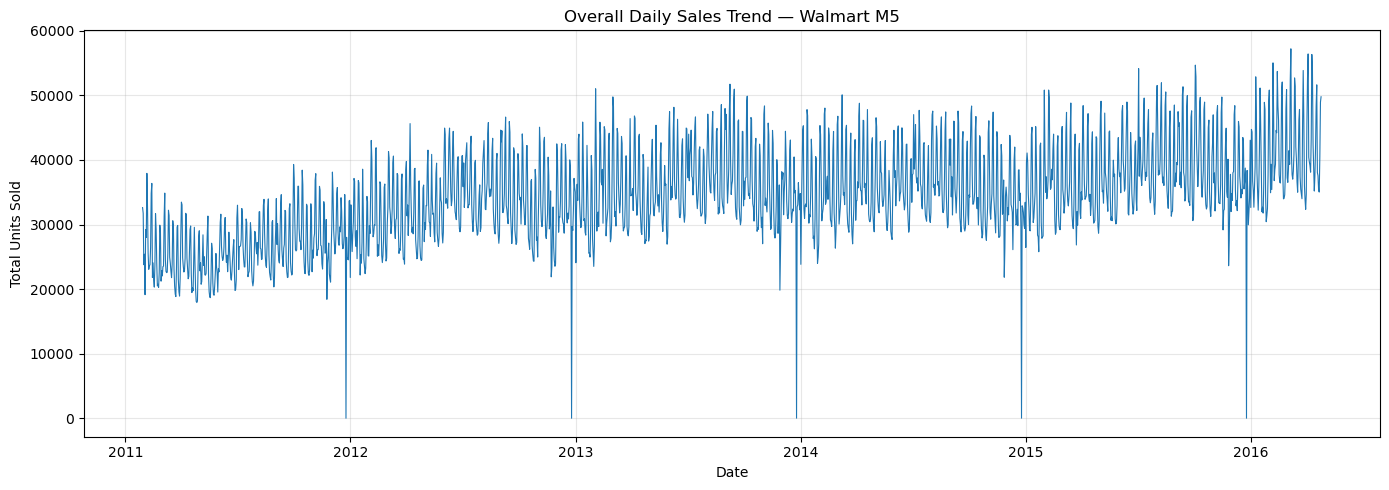

In [20]:

# Aggregate total units sold across all products and stores
daily_sales = sales[day_cols].sum(axis=0)

# Match daily identifiers to calendar dates
daily_sales_df = pd.DataFrame({
    "d": daily_sales.index,
    "total_sales": daily_sales.values
})

daily_sales_df = daily_sales_df.merge(
    calendar[["d", "date"]],
    on="d",
    how="left",
    validate="one_to_one"
)

daily_sales_df = daily_sales_df.sort_values("date")

# Visualize daily sales
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales_df["date"],
    daily_sales_df["total_sales"],
    linewidth=0.8
)

plt.title("Overall Daily Sales Trend — Walmart M5")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 4.7 Investigation of Unusually Low Sales Days

In [22]:

# Identify the 10 lowest-sales days
lowest_sales_days = daily_sales_df.nsmallest(
    10, "total_sales"
)

# Join calendar event information
lowest_sales_days = lowest_sales_days.merge(
    calendar[
        ["date", "weekday", "event_name_1", "event_type_1"]
    ],
    on="date",
    how="left",
    validate="one_to_one"
)

# Display results
lowest_sales_days[
    ["date", "weekday", "total_sales",
     "event_name_1", "event_type_1"]
]


,date,weekday,total_sales,event_name_1,event_type_1
0,2012-12-25,Tuesday,11,Christmas,National
1,2011-12-25,Sunday,13,Christmas,National
2,2015-12-25,Friday,14,Christmas,National
3,2013-12-25,Wednesday,20,Christmas,National
4,2014-12-25,Thursday,20,Christmas,National
5,2011-04-27,Wednesday,17929,NaN,NaN
6,2011-04-26,Tuesday,18113,Pesach End,Religious
7,2011-04-28,Thursday,18145,NaN,NaN
8,2011-11-24,Thursday,18427,Thanksgiving,National
9,2011-05-19,Thursday,18684,NaN,NaN


### 4.8 Weekly Sales Seasonality

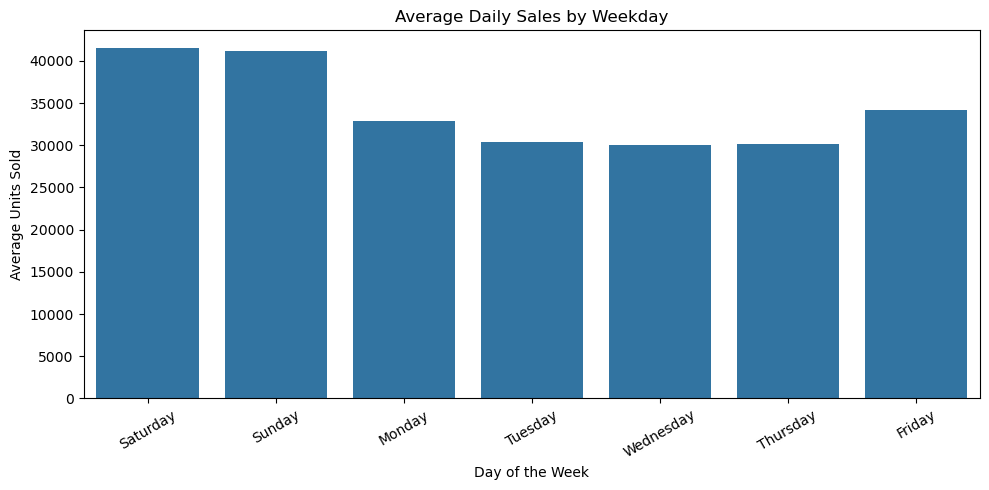

,wday,weekday,total_sales
0,1,Saturday,41546.894161
1,2,Sunday,41130.021898
2,3,Monday,32852.967033
3,4,Tuesday,30368.780220
4,5,Wednesday,30010.021978
5,6,Thursday,30205.007326
6,7,Friday,34225.985348


In [23]:

# Calculate average daily sales by weekday
weekday_sales = (
    daily_sales_df
    .merge(
        calendar[["date", "weekday", "wday"]],
        on="date",
        how="left",
        validate="one_to_one"
    )
    .groupby(["wday", "weekday"])["total_sales"]
    .mean()
    .reset_index()
    .sort_values("wday")
)

# Visualize
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_sales,
    x="weekday",
    y="total_sales"
)

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Display numerical results
weekday_sales


### 4.9 Monthly Sales Seasonality

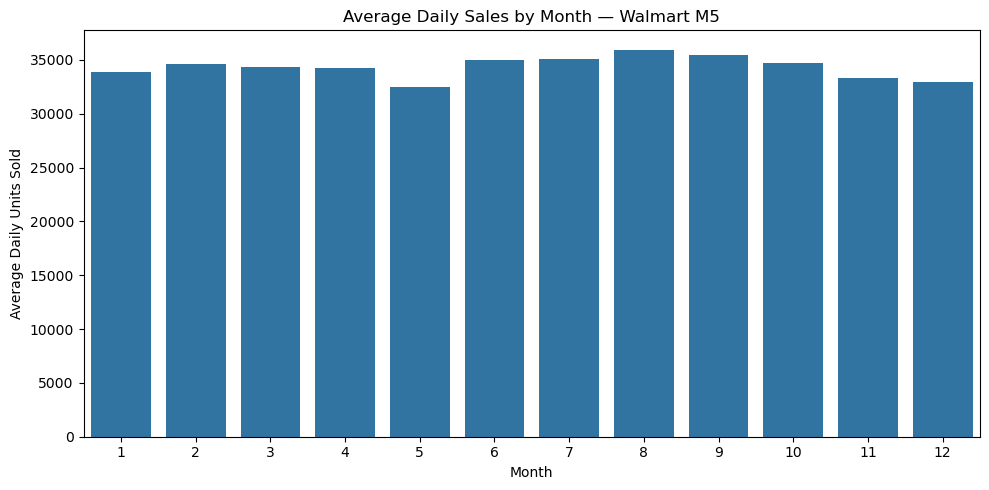

,month,total_sales
0,1,33832.348101
1,2,34644.641176
2,3,34339.838710
3,4,34258.683908
4,5,32503.851613
5,6,35001.413333
6,7,35122.419355
7,8,35946.645161
8,9,35479.260000
9,10,34713.477419


In [24]:

# Merge monthly information
monthly_sales = (
    daily_sales_df
    .merge(
        calendar[["date", "month"]],
        on="date",
        how="left",
        validate="one_to_one"
    )
    .groupby("month")["total_sales"]
    .mean()
    .reset_index()
)

# Visualize monthly patterns
plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_sales,
    x="month",
    y="total_sales"
)

plt.title("Average Daily Sales by Month — Walmart M5")
plt.xlabel("Month")
plt.ylabel("Average Daily Units Sold")
plt.tight_layout()
plt.show()

monthly_sales


### 4.10 Sales Trends by Product Category

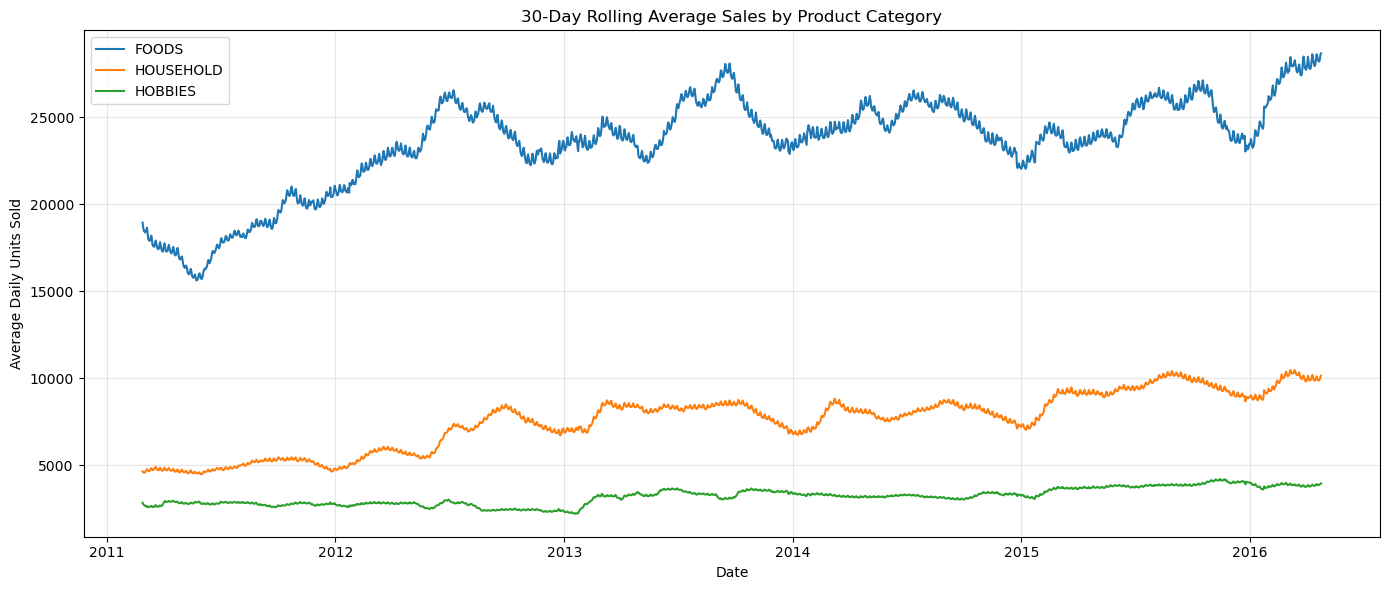

In [25]:

# Aggregate daily sales by product category
category_daily_sales = (
    sales.groupby("cat_id")[day_cols]
    .sum()
    .T
)

# Attach actual dates
category_daily_sales["date"] = pd.to_datetime(
    calendar.set_index("d")
    .loc[day_cols, "date"]
    .values
)

category_daily_sales = category_daily_sales.set_index("date")

# Calculate 30-day rolling averages
category_rolling = category_daily_sales.rolling(
    window=30,
    min_periods=30
).mean()

# Plot category trends
plt.figure(figsize=(14, 6))

for category in ["FOODS", "HOUSEHOLD", "HOBBIES"]:
    plt.plot(
        category_rolling.index,
        category_rolling[category],
        label=category
    )

plt.title("30-Day Rolling Average Sales by Product Category")
plt.xlabel("Date")
plt.ylabel("Average Daily Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 4.11 Average Daily Sales by Product Category

In [26]:

# Calculate average daily units sold by category
category_summary = (
    category_daily_sales
    .agg(["mean", "sum"])
    .T
    .rename(columns={
        "mean": "avg_daily_sales",
        "sum": "total_units_sold"
    })
)

# Calculate contribution to overall sales
category_summary["sales_share_pct"] = (
    category_summary["total_units_sold"]
    / category_summary["total_units_sold"].sum()
    * 100
)

print(category_summary.round(2))


           avg_daily_sales  total_units_sold  sales_share_pct
cat_id                                                       
FOODS             23570.28        45089939.0            68.63
HOBBIES            3201.67         6124800.0             9.32
HOUSEHOLD          7569.61        14480670.0            22.04


## 5. Dataset Relationship Validation
### 5.1 Key Coverage Checks

In [27]:

# Check whether every sales day exists in calendar
missing_days = set(day_cols) - set(calendar["d"])

# Check product-store combinations across datasets
sales_keys = pd.MultiIndex.from_frame(
    sales[["store_id", "item_id"]]
)

price_keys = pd.MultiIndex.from_frame(
    prices[["store_id", "item_id"]].drop_duplicates()
)

missing_product_store = sales_keys.difference(price_keys)

# Check weekly identifiers
missing_weeks = (
    set(prices["wm_yr_wk"])
    - set(calendar["wm_yr_wk"])
)

print("Sales days missing from calendar:", len(missing_days))
print("Product-store pairs missing from prices:",
      len(missing_product_store))
print("Price weeks missing from calendar:",
      len(missing_weeks))


Sales days missing from calendar: 0
Product-store pairs missing from prices: 0
Price weeks missing from calendar: 0



## 6. Exploratory Data Analysis Summary

### Dataset Overview
- Calendar: 1,969 daily records
- Selling prices: 6,841,121 weekly price records
- Historical sales: 30,490 product-store series
- Historical sales period: 1,913 days
- Product categories: FOODS, HOUSEHOLD, HOBBIES

### Data Quality
- No missing values in recorded daily sales or pricing records
- No duplicate sales series or product-store-week price keys
- Calendar event fields contain expected null values
- Dataset relationship key-coverage checks passed

### Key Findings
1. Selling prices are strongly right-skewed.
2. 4.44% of price records exceed the IQR upper fence.
3. 68.20% of daily sales observations contain zero sales.
4. FOODS contributes 68.63% of total units sold.
5. Weekend sales are substantially higher than weekday sales.
6. Christmas Day consistently exhibits exceptionally low recorded sales.
7. Aggregate sales generally increase over time.
8. Price-history coverage differs across product-store combinations.

### Implications for Forecasting
- Evaluate models across product categories.
- Include calendar, holiday, and historical demand features.
- Investigate zero-sales periods and missing price coverage.
- Use chronological train-validation-test splits.
- Prevent data leakage when creating lag and rolling features.
- Compare machine learning models against simple forecasting baselines.

### Conclusion
The Walmart M5 dataset provides a suitable foundation for
developing a product-store-level demand forecasting system.

The next phase will focus on data preprocessing, feature
engineering, forecasting model training, and evaluation.
